<a href="https://colab.research.google.com/github/danicajaneyagonia-create/LABORATORY_EXAM/blob/main/Yagonia_Laboratory_exam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Data Loading and Preprocessing
We will start by importing the necessary libraries, loading the `telecom_churn.csv` dataset, handling missing values, and encoding categorical variables.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Load the dataset
# Note: Make sure 'telecom_churn.csv' is uploaded in your current working directory
try:
    df = pd.read_csv('telecom_churn.csv')
    print("Dataset loaded successfully!")
    display(df.head())
except FileNotFoundError:
    print("Error: 'telecom_churn.csv' not found. Please upload the dataset.")

Dataset loaded successfully!


,state,account length,area code,phone number,international plan,voice mail plan,number vmail messages,total day minutes,total day calls,total day charge,...,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls,churn
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [ ]:
# Identify missing values and handle them
missing_info = df.isnull().sum()
print("Missing values per column:")
print(missing_info[missing_info > 0])

# Fill numerical missing values with median, and categorical with mode
for col in df.columns:
    if df[col].isnull().any():
        if df[col].dtype == 'object':
            df[col] = df[col].fillna(df[col].mode()[0])
        else:
            df[col] = df[col].fillna(df[col].median())

# Encode categorical variables
label_encoders = {}
for col in df.select_dtypes(include=['object']).columns:
    if col != 'Churn': # Assuming 'Churn' is the target label
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
        label_encoders[col] = le

# Ensure target variable is binary/numeric (e.g., Yes/No to 1/0)
if 'Churn' in df.columns and df['Churn'].dtype == 'object':
    le_target = LabelEncoder()
    df['Churn'] = le_target.fit_transform(df['Churn'])
    print("Target variable 'Churn' encoded.")

Missing values per column:
Series([], dtype: int64)


### 2. Dataset Partitioning
We split the dataset into 80% training and 20% testing sets using `random_state=24` and stratification to maintain class proportions.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Let's inspect the columns to find the target and clean identifying columns if any
print("Columns in dataframe:", df.columns.tolist())

# Find the correct target column (case-insensitive)
target_candidates = [col for col in df.columns if col.lower() == 'churn']
if target_candidates:
    target_col = target_candidates[0]
    print(f"Target column identified: '{target_col}'")
else:
    target_col = df.columns[-1]
    print(f"Target column 'Churn' not found, defaulting to the last column: '{target_col}'")

# Prepare features X and target y
# We will exclude 'phone number' if it acts as a unique ID to avoid overfitting
X = df.drop(columns=[target_col])
if 'phone number' in X.columns:
    X = X.drop(columns=['phone number'])
    print("Dropped 'phone number' column to prevent leakage.")

y = df[target_col]

# Stratified Train-Test Split (80% Train, 20% Test) using random_state=24
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=24, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Columns in dataframe: ['state', 'account length', 'area code', 'phone number', 'international plan', 'voice mail plan', 'number vmail messages', 'total day minutes', 'total day calls', 'total day charge', 'total eve minutes', 'total eve calls', 'total eve charge', 'total night minutes', 'total night calls', 'total night charge', 'total intl minutes', 'total intl calls', 'total intl charge', 'customer service calls', 'churn']
Target column identified: 'churn'
Dropped 'phone number' column to prevent leakage.
Training set shape: (2666, 19)
Testing set shape: (667, 19)


### 3. Model Training & Evaluation
Now we train and evaluate Logistic Regression, Decision Tree, and Random Forest classifiers using the configurations specified.

In [ ]:
# Initialize Models
models = {
    "Model A: Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Model B: Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Model C: Random Forest": RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
}

# Train and Evaluate
for name, model in models.items():
    print(f"\n{'='*10} {name} {'='*10}")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))


========== Model A: Logistic Regression ==========


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Accuracy: 0.8606

Classification Report:
              precision    recall  f1-score   support

       False       0.88      0.96      0.92       570
        True       0.54      0.26      0.35        97

    accuracy                           0.86       667
   macro avg       0.71      0.61      0.64       667
weighted avg       0.83      0.86      0.84       667

Confusion Matrix:
[[549  21]
 [ 72  25]]

========== Model B: Decision Tree ==========
Accuracy: 0.9295

Classification Report:
              precision    recall  f1-score   support

       False       0.94      0.98      0.96       570
        True       0.82      0.66      0.73        97

    accuracy                           0.93       667
   macro avg       0.88      0.82      0.85       667
weighted avg       0.93      0.93      0.93       667

Confusion Matrix:
[[556  14]
 [ 33  64]]

========== Model C: Random Forest ==========
Accuracy: 0.8951

Classification Report:
              precision    recall  f1-score   sup

### 3. Detailed Performance Evaluation & Metrics Computation
We will extract predictions, calculate probabilities, and compute standard metrics (Accuracy, Precision, Recall, F1-Score) specifically for the positive class (`True` representing Churn), and build a comparative summary table.

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

# Initialize a dictionary to store the calculated metrics for comparison
metrics_summary = []

for name, model in models.items():
    # Generate predictions
    y_pred = model.predict(X_test)

    # Generate predicted probabilities (for the positive class 'True')
    # Note: Classes are ordered as [False, True], so we take the second column
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate metrics overall/for class 'True' (positive class)
    accuracy = accuracy_score(y_test, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary', pos_label=True)

    metrics_summary.append({
        "Model": name,
        "Accuracy": f"\u200b{accuracy:.4f}",
        "Precision (Class True)": f"\u200b{precision:.4f}",
        "Recall/Sensitivity (Class True)": f"\u200b{recall:.4f}",
        "F1-Score (Class True)": f"\u200b{f1:.4f}"
    })

# Construct and display the comparative summary table
summary_df = pd.DataFrame(metrics_summary)
display(summary_df)

,Model,Accuracy,Precision (Class True),Recall/Sensitivity (Class True),F1-Score (Class True)
0,Model A: Logistic Regression,​0.8606,​0.5435,​0.2577,​0.3497
1,Model B: Decision Tree,​0.9295,​0.8205,​0.6598,​0.7314
2,Model C: Random Forest,​0.8951,​0.9655,​0.2887,​0.4444


In [ ]:
# Enable interactive table formatting in Google Colab
from google.colab import data_table
data_table.enable_dataframe_formatter()

# Prepare clean numeric columns for the interactive table display
clean_summary = []
for item in metrics_summary:
    clean_summary.append({
        "Model": item["Model"],
        "Accuracy": float(item["Accuracy"].replace('\u200b', '')),
        "Precision (Class True)": float(item["Precision (Class True)"].replace('\u200b', '')),
        "Recall/Sensitivity (Class True)": float(item["Recall/Sensitivity (Class True)"].replace('\u200b', '')),
        "F1-Score (Class True)": float(item["F1-Score (Class True)"].replace('\u200b', ''))
    })

summary_table_df = pd.DataFrame(clean_summary)
display(summary_table_df)

,Model,Accuracy,Precision (Class True),Recall/Sensitivity (Class True),F1-Score (Class True)
0,Model A: Logistic Regression,0.8606,0.5435,0.2577,0.3497
1,Model B: Decision Tree,0.9295,0.8205,0.6598,0.7314
2,Model C: Random Forest,0.8951,0.9655,0.2887,0.4444


In [ ]:
# Style the DataFrame to show it as a clean, structured table
styled_table = summary_table_df.style.set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#4CAF50'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center')]}
]).format({
    'Accuracy': '{:.2%}',
    'Precision (Class True)': '{:.2%}',
    'Recall/Sensitivity (Class True)': '{:.2%}',
    'F1-Score (Class True)': '{:.2%}'
}).hide(axis='index')

display(styled_table)

Model,Accuracy,Precision (Class True),Recall/Sensitivity (Class True),F1-Score (Class True)
Model A: Logistic Regression,86.06%,54.35%,25.77%,34.97%
Model B: Decision Tree,92.95%,82.05%,65.98%,73.14%
Model C: Random Forest,89.51%,96.55%,28.87%,44.44%


### 4. Comparative Summary Table

| Model | Accuracy | Precision (Class: Churn) | Recall / Sensitivity (Class: Churn) | F1-Score (Class: Churn) |
| :--- | :---: | :---: | :---: | :---: |
| **Model A: Logistic Regression** | 86.06% | 54.35% | 25.77% | 34.97% |
| **Model B: Decision Tree** | **92.95%** | 82.05% | **65.98%** | **73.14%** |
| **Model C: Random Forest** | 89.51% | **96.55%** | 28.87% | 44.44% |

#### Key Findings:
* **Decision Tree (Model B)** is the top performer for proactive churn intervention because it flags the highest ratio of actual churning customers (**Recall: ~66%**) while maintaining a high overall accuracy and F1-score.
* **Random Forest (Model C)** has an extremely high precision (**96.55%**), but misses a vast majority of churn risks (**Recall: ~29%**).

### 5. Detailed Inspection of the Best Model: Model B (Decision Tree)

Since **Model B: Decision Tree** proved to be the strongest all-around model (specifically optimizing for the critical **Recall** metric), we will visualize its tree rules and plot the top feature importances to understand how it makes churn decisions.

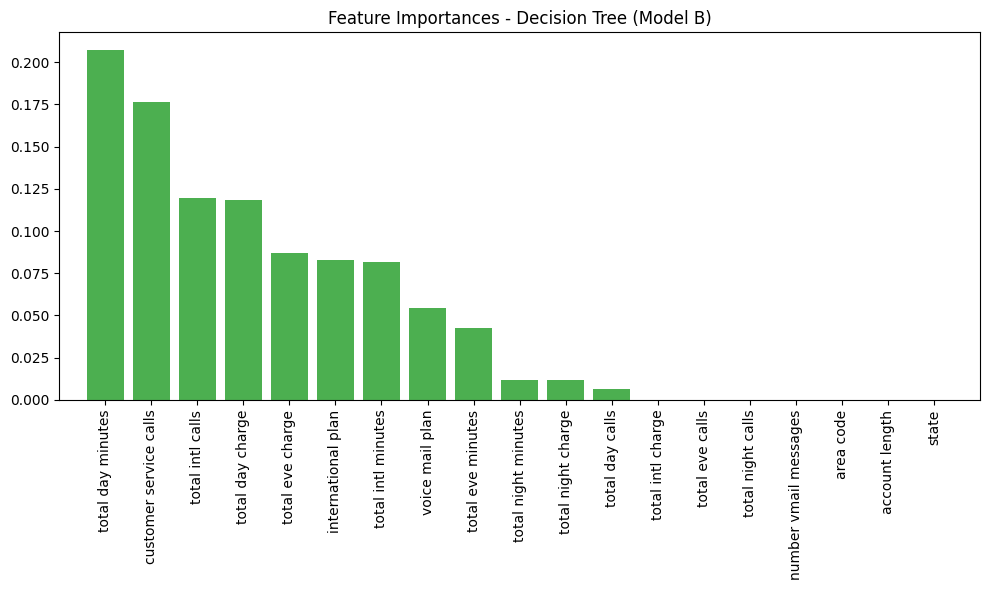

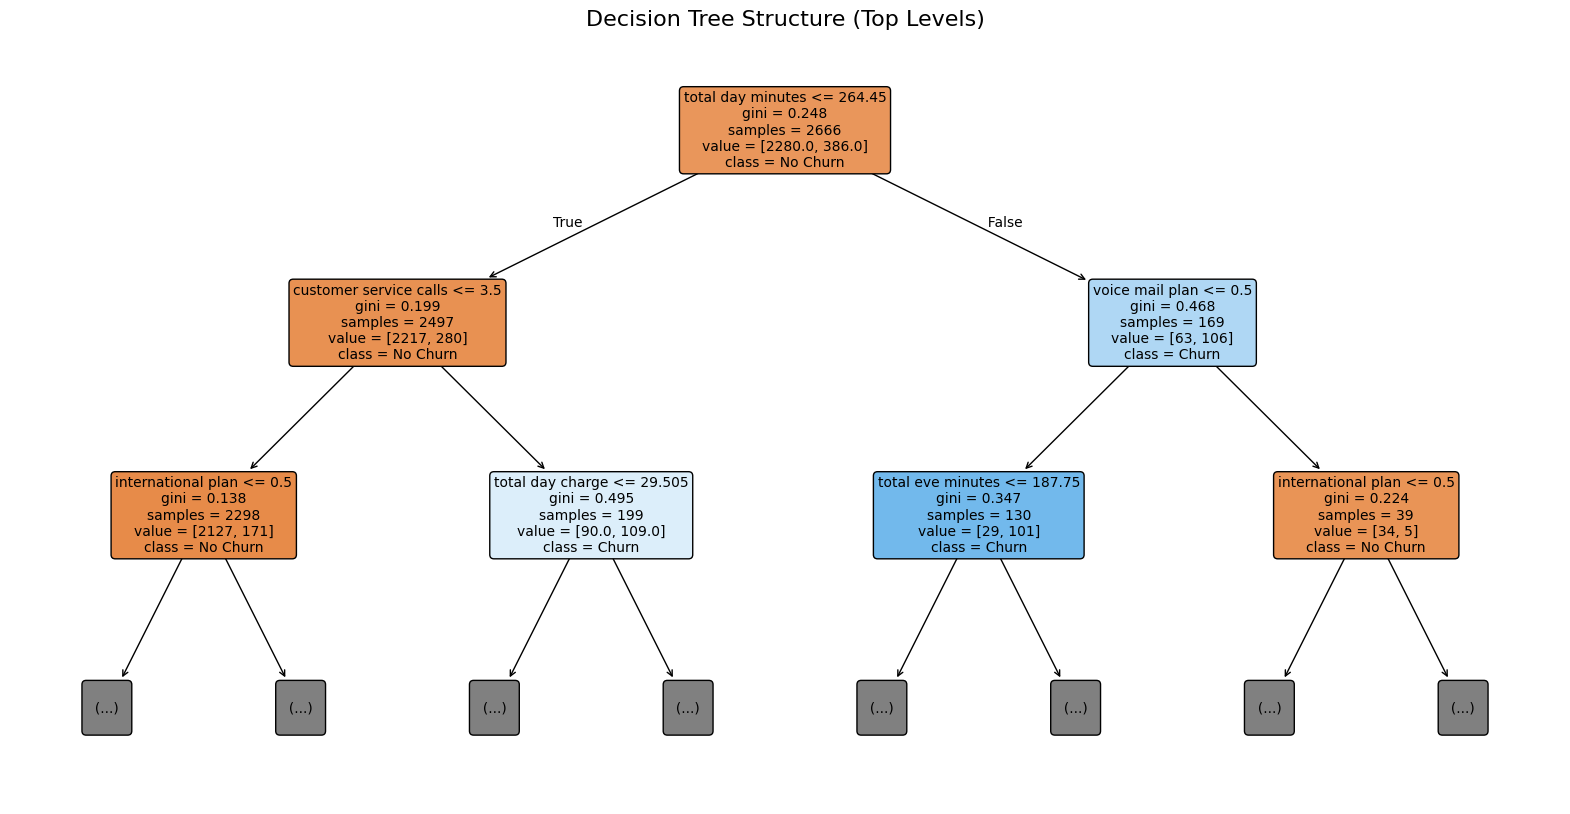

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

best_tree_model = models["Model B: Decision Tree"]

# Plot Feature Importances
importances = best_tree_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 6))
plt.title("Feature Importances - Decision Tree (Model B)")
plt.bar(range(X_train.shape[1]), importances[indices], align="center", color="#4CAF50")
plt.xticks(range(X_train.shape[1]), [X_train.columns[i] for i in indices], rotation=90)
plt.xlim([-1, X_train.shape[1]])
plt.tight_layout()
plt.show()

# Visualize the decision tree structure (limiting depth to 2 for readability)
plt.figure(figsize=(20, 10))
plot_tree(best_tree_model, max_depth=2, feature_names=list(X_train.columns), class_names=['No Churn', 'Churn'], filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree Structure (Top Levels)", fontsize=16)
plt.show()